# Human Activity Recognition with an HMM

I recorded four activities on my phone (standing, walking, jumping, still) and built an HMM from scratch to work out the activity from the sensor data.

## Setup

All my settings are here. Each window is 256 samples (2.56 s at 100 Hz). My steps take about 0.8 s, so one window holds around 3 steps. Windows overlap by 50%.

In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_DIR = Path("Data/raw")
CLEANED_DIR = Path("Data/cleaned")
TEST_DIR = Path("Data/test")
FIGURE_DIR = Path("figures")
for folder in (CLEANED_DIR, TEST_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# hidden states
ACTIVITIES = ["Standing", "Walking", "Jumping", "Still"]
N_STATES = len(ACTIVITIES)

#Pre-processing choices
TARGET_HZ = 100
TRIM_SECONDS = 1.0
WINDOW_SIZE = 256
WINDOW_STEP = 128

#Evaluation 
TEST_NUMBERS = {17, 18, 19, 20}
RANDOM_SEED = 42

#Chart styling
ACTIVITY_COLORS = dict(zip(ACTIVITIES,["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK,  MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "font.family": "sans-serif", "font.sans-serif": ["segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "axes.titlesize": 11, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

def save_figure(name):
    plt.savefig(FIGURE_DIR / f"{name}.png")

## Cleaning the data

My phone records at about 102 Hz, and the accelerometer and gyroscope files don't always have the same number of rows. I resample both to 100 Hz so they line up. I also cut 1 s from each end, because that's when I was touching the phone to start and stop.

In [19]:
AXES = ["x", "y", 'z']

def read_sensor(path):
    data = pd.read_csv(path)
    return data.drop_duplicates("seconds_elapsed").sort_values("seconds_elapsed")

def load_recording(folder, activity):
    accel = read_sensor(folder / "Accelerometer.csv")
    gyro = read_sensor(folder / "Gyroscope.csv")

    #keep only the time span that noth sensors cover
    start = max(accel.seconds_elapsed.iloc[0], gyro.seconds_elapsed.iloc[0]) + TRIM_SECONDS
    end = min(accel.seconds_elapsed.iloc[-1], gyro.seconds_elapsed.iloc[-1]) - TRIM_SECONDS
    new_clock = np.arange(start, end, 1 / TARGET_HZ)

    cleaned = pd.DataFrame({"timestamp_s": new_clock - start})
    for axis in AXES:
        cleaned[f"acc_{axis}"] = np.interp(new_clock, accel.seconds_elapsed, accel[axis])
    for axis in AXES:
        cleaned[f"gyro_{axis}"] = np.interp(new_clock, gyro.seconds_elapsed, gyro[axis])
    cleaned["activity"] = activity
    cleaned["recording"] = folder.name
    return cleaned 

#Describe the recording
def recording_info(folder, activity):
    metadata = pd.read_csv(folder / "Metadata.csv").iloc[0]
    accel = read_sensor(folder / "Accelerometer.csv")
    gyro = read_sensor(folder / "Gyroscope.csv")
    gaps = accel.seconds_elapsed.diff().dropna()
    return {
        "recording": folder.name, "activity": activity,
        "device": metadata["device name"],
        "raw_hz": 1 / gaps.median(), "duration_s": accel.seconds_elapsed.iloc[-1] - accel.seconds_elapsed.iloc[0],
        "largest_gap_s": gaps.max(), "missing_values": int(accel.isna().sum().sum() + gyro.isna().sum().sum()),
    }

Clean all 80 recordings, save them, and check for missing values or gaps.

In [20]:
recordings, info_rows = {}, []
for activity in ACTIVITIES:
    for folder in sorted((RAW_DIR / activity).iterdir()):
        cleaned = load_recording(folder, activity)
        cleaned.to_csv(CLEANED_DIR / f"{folder.name}.csv", index=False)
        recordings[folder.name] = cleaned
        info_rows.append(recording_info(folder, activity))

info = pd.DataFrame(info_rows)
summary = info.groupby("activity").agg(
    files=("recording", "count"), total_seconds=("duration_s", "sum"),
    shortest_s=("duration_s", "min"), longest_s=("duration_s", "max"),
    raw_hz=("raw_hz", "median"), largest_gap_s=("largest_gap_s", "max"), missing_values=("missing_values", "sum"),
).reindex(ACTIVITIES).round(2)
print("Device used:", ", ".join(info.device.unique()))
summary

Device used: SM-A235F


,files,total_seconds,shortest_s,longest_s,raw_hz,largest_gap_s,missing_values
activity,,,,,,,
Standing,20,212.36,10.04,11.30,102.07,0.01,0
Walking,20,207.89,9.60,11.30,102.07,0.01,0
Jumping,20,201.60,8.60,10.65,102.07,0.01,0
Still,20,210.25,9.57,11.69,102.07,0.01,0


### Raw signals

One recording per activity. I use magnitude so the result doesn't depend on how the phone is held. Each panel has its own scale, because jumping is far stronger than still.

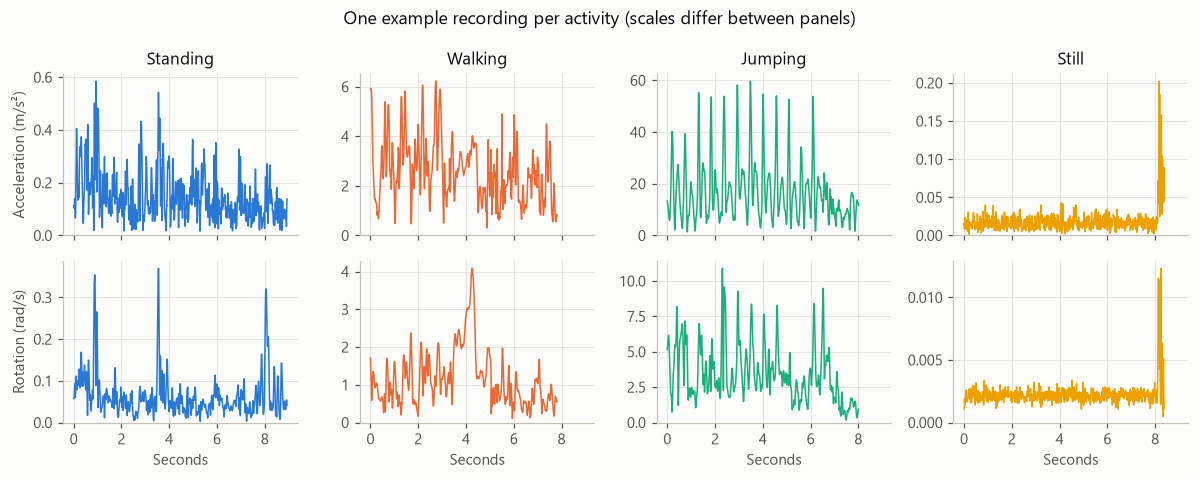

In [21]:
def magnitude(frame, sensor):
    return np.sqrt(sum(frame[f"{sensor}_{axis}"] ** 2 
    for axis in AXES)).to_numpy()

fig, axes = plt.subplots(2, N_STATES, figsize=(11, 4.4), sharex=True)
for column, activity in enumerate(ACTIVITIES):
    sample = recordings[f"{activity}_05"]
    for row, (sensor, unit) in enumerate([("acc", "Acceleration (m/s²)"), ("gyro", "Rotation(rad/s)")]):
        axes[row, column].plot(sample.timestamp_s,
        magnitude(sample, sensor), color=ACTIVITY_COLORS[activity], linewidth=1)
        axes[row, column].set_ylim(bottom=0)
    axes[0, column].set_title(activity)
    axes[1, column].set_xlabel("Seconds")
axes[0, 0].set_ylabel("Acceleration (m/s²)")
axes[1, 0].set_ylabel("Rotation (rad/s)")
fig.suptitle("One example recording per activity (scales differ between panels)", color=INK, fontsize=12)
fig.tight_layout()
save_figure("01_sample_signals")
plt.show()

## Features

Each window gets 10 features, 6 from the time domain and 4 from the FFT.

- **Variance, SMA and RMS** show how strong the movement is, which separates the activities well.
- **Correlation between axes** shows the direction of movement. Jumping is mostly up and down.
- **Dominant frequency** gives the rhythm of the movement, such as my steps or jumps.
- **Spectral energy** shows the total strength across frequencies.
- **Spectral entropy** shows how messy the signal is. A still phone is mostly random noise.

I take the log of the strength features because their values cover a huge range.

In [22]:
LOG_FLOOR = 1e-10


def safe_log(value):
    """Logarithm that stays defined when the value is exactly zero."""
    return np.log10(value + LOG_FLOOR)


def correlation(a, b):
    """How strongly two axes move together: +1 together, -1 opposite, 0 unrelated."""
    if a.std() == 0 or b.std() == 0:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])


def spectrum(signal):
    """Return frequencies and their power, leaving out the 0 Hz average level."""
    faded = (signal - signal.mean()) * np.hanning(len(signal))
    power = np.abs(np.fft.rfft(faded)) ** 2 / len(signal)
    frequencies = np.fft.rfftfreq(len(signal), d=1 / TARGET_HZ)
    return frequencies[1:], power[1:]


def spectral_entropy(power):
    """0 means one pure rhythm, 1 means power spread evenly like random noise."""
    share = power / (power.sum() + LOG_FLOOR)
    return float(-(share * np.log(share + LOG_FLOOR)).sum() / np.log(len(share)))


def window_features(window):
    """Turn one window of readings into one observation (a dictionary of features)."""
    acc_mag, gyro_mag = magnitude(window, "acc"), magnitude(window, "gyro")
    acc_freqs, acc_power = spectrum(acc_mag)
    gyro_freqs, gyro_power = spectrum(gyro_mag)
    return {
        # Time domain
        "acc_log_var": safe_log(acc_mag.var()),
        "gyro_log_var": safe_log(gyro_mag.var()),
        "acc_log_sma": safe_log(window[["acc_x", "acc_y", "acc_z"]].abs().sum(axis=1).mean()),
        "gyro_log_rms": safe_log(np.sqrt((gyro_mag ** 2).mean())),
        "acc_corr_xy": correlation(window.acc_x.to_numpy(), window.acc_y.to_numpy()),
        "acc_corr_yz": correlation(window.acc_y.to_numpy(), window.acc_z.to_numpy()),
        # Frequency domain (from the FFT)
        "acc_dom_freq": acc_freqs[acc_power.argmax()],
        "acc_log_energy": safe_log(acc_power.sum()),
        "acc_entropy": spectral_entropy(acc_power),
        "gyro_dom_freq": gyro_freqs[gyro_power.argmax()],
    }


def recording_features(frame):
    """Slide the window along one recording and return a table with one row per window."""
    rows = []
    for start in range(0, len(frame) - WINDOW_SIZE + 1, WINDOW_STEP):
        features = window_features(frame.iloc[start:start + WINDOW_SIZE])
        features.update(activity=frame.activity.iloc[0], recording=frame.recording.iloc[0], window_start_s=start / TARGET_HZ)
        rows.append(features)
    return pd.DataFrame(rows)


features_by_recording = {name: recording_features(frame) for name, frame in recordings.items()}
all_features = pd.concat(features_by_recording.values(), ignore_index=True)
FEATURE_NAMES = [c for c in all_features.columns if c not in ("activity", "recording", "window_start_s")]
print(f"{len(all_features)} windows, {len(FEATURE_NAMES)} features each")
print("Windows per activity:", all_features.activity.value_counts().reindex(ACTIVITIES).to_dict())
print("Windows per recording: min", all_features.groupby("recording").size().min(), "max", all_features.groupby("recording").size().max())

408 windows, 10 features each
Windows per activity: {'Standing': 103, 'Walking': 102, 'Jumping': 98, 'Still': 105}
Windows per recording: min 4 max 6


Checking whether the features actually separate the activities, before building any model.

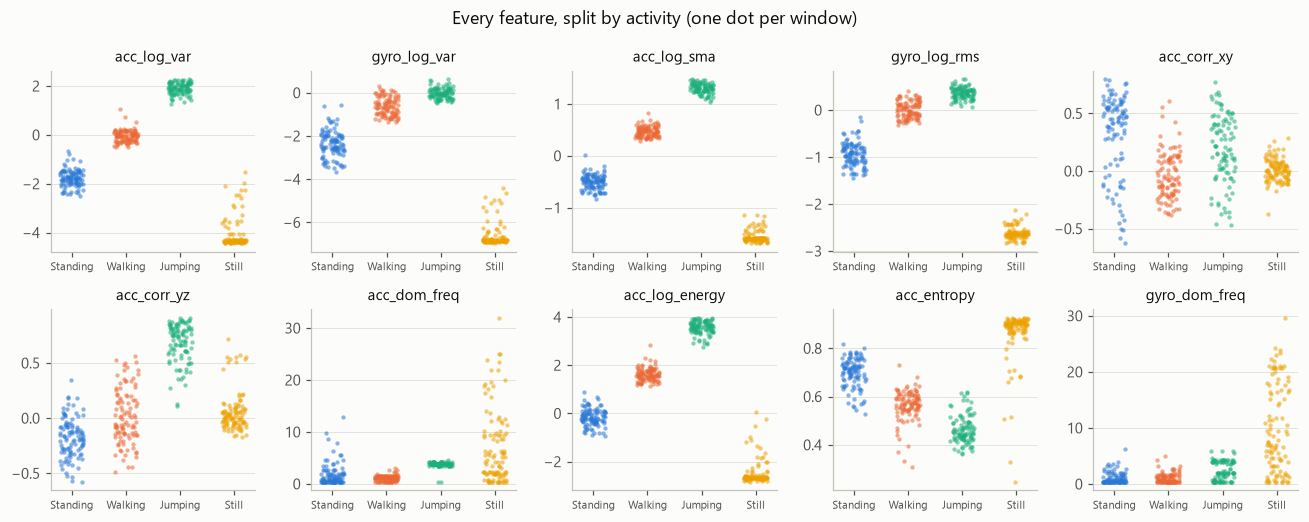

In [23]:
generator = np.random.default_rng(RANDOM_SEED)
fig, axes = plt.subplots(2, 5, figsize=(12, 4.8))
for panel, name in zip(axes.flat, FEATURE_NAMES):
    for position, activity in enumerate(ACTIVITIES):
        values = all_features.loc[all_features.activity == activity, name]
        jitter = generator.uniform(-0.22, 0.22, len(values))
        panel.scatter(position + jitter, values, s=8, alpha=0.55, color=ACTIVITY_COLORS[activity], linewidths=0)
    panel.set_title(name, fontsize=10)
    panel.set_xticks(range(N_STATES), ACTIVITIES, fontsize=7)
    panel.grid(axis="x", visible=False)
fig.suptitle("Every feature, split by activity (one dot per window)", color=INK, fontsize=12)
fig.tight_layout()
save_figure("02_feature_distributions")
plt.show()

## Train and test split

Recordings 1-16 are for training and 17-20 are for testing. I split by whole recording, because neighbouring windows overlap and would otherwise leak into the test. Each recording has one activity, so I join the test recordings into two files to create activity changes.

In [24]:
TEST_ORDER = {
    "test_sequence_A": ["Still_17", "Standing_17", "Walking_17", "Jumping_17", "Walking_18", "Standing_18", "Still_18", "Jumping_18"],
    "test_sequence_B": ["Standing_19", "Walking_19", "Jumping_19", "Still_19", "Jumping_20", "Standing_20", "Walking_20", "Still_20"],
}


def recording_number(name):
    return int(name.split("_")[1])


train_names = [name for name in recordings if recording_number(name) not in TEST_NUMBERS]

# Write the two test files, then read them back so that testing truly uses those files
for sequence_name, members in TEST_ORDER.items():
    pd.concat([recordings[m] for m in members]).to_csv(TEST_DIR / f"{sequence_name}.csv", index=False)


def load_test_sequence(sequence_name):
    """Read a test file and compute features one recording at a time, in the file's order."""
    data = pd.read_csv(TEST_DIR / f"{sequence_name}.csv")
    return [recording_features(part) for _, part in data.groupby("recording", sort=False)]


test_tables = {name: load_test_sequence(name) for name in TEST_ORDER}
assert not set(train_names) & {m for members in TEST_ORDER.values() for m in members}, "Train and test overlap"
print(len(train_names), "training recordings;", sum(len(m) for m in TEST_ORDER.values()), "test recordings; no overlap")

64 training recordings; 16 test recordings; no overlap


## Normalisation

I use z-scores so all features share a similar scale. The mean and standard deviation come from training data only. My recordings have no real activity changes, so I join training recordings in random order. This means the switching probabilities come from the shuffling, not from real behaviour.

In [25]:
N_TRAINING_SHUFFLES = 5


def make_scaler(names):
    """Learn each feature's mean and spread from the given recordings only."""
    table = pd.concat([features_by_recording[name] for name in names])[FEATURE_NAMES]
    return table.mean().to_numpy(), table.std().to_numpy()


def to_arrays(tables, scaler):
    """Join feature tables into a z-scored matrix X and an array of state numbers y."""
    table = pd.concat(tables)
    X = (table[FEATURE_NAMES].to_numpy() - scaler[0]) / scaler[1]
    y = table.activity.map(ACTIVITIES.index).to_numpy()
    return X, y


def make_sequences(names, scaler, seed=RANDOM_SEED):
    """Build training sequences by joining recordings in several random orders."""
    generator = np.random.default_rng(seed)
    return [
        to_arrays([features_by_recording[names[i]] for i in generator.permutation(len(names))], scaler)
        for _ in range(N_TRAINING_SHUFFLES)
    ]


scaler = make_scaler(train_names)
train_sequences = make_sequences(train_names, scaler)
test_sequences = {name: to_arrays(tables, scaler) for name, tables in test_tables.items()}
print("Training sequences:", len(train_sequences), "each with", len(train_sequences[0][0]), "windows")
print("Test windows:", {name: len(seq[0]) for name, seq in test_sequences.items()})

Training sequences: 5 each with 326 windows
Test windows: {'test_sequence_A': 42, 'test_sequence_B': 40}


## The HMM

- **Hidden states:** the four activities
- **Observations:** the 10 features of each window
- **Emissions:** one Gaussian per feature for each activity
- **Viterbi** finds the most likely full sequence of activities, and this is what I score with sensitivity, specificity and accuracy.
- **Forward-Backward** gives the probability of each activity for each window.
- **Baum-Welch** refines the parameters and stops when the log-likelihood per window improves by less than 0.0001. It maximises likelihood rather than accuracy, so I compare the scores before and after.

In [26]:
class GaussianHMM:
    """A Hidden Markov Model with one diagonal Gaussian per state, built using numpy only.

    Parameters learned:
        initial    : pi, shape (n_states,), the chance of starting in each state
        transition : A,  shape (n_states, n_states), where row i column j is P(next = j | now = i)
        means, variances : B, shape (n_states, n_features), one bell curve per state and feature
    """

    def __init__(self, n_states, var_floor=1e-3, smoothing=1e-3, tol=1e-4, max_iter=200):
        self.n_states = n_states
        self.var_floor = var_floor    # smallest allowed variance
        self.smoothing = smoothing    # small extra count so no probability becomes exactly 0
        self.tol = tol                # convergence threshold, per window
        self.max_iter = max_iter      # safety limit, not the normal way to stop
        self.log_likelihoods = []
        self.converged = False

    def fit_supervised(self, sequences):
        """Calculate all parameters directly by counting, using the true labels."""
        X_all = np.vstack([X for X, _ in sequences])
        y_all = np.concatenate([y for _, y in sequences])
        self.means = np.array([X_all[y_all == k].mean(axis=0) for k in range(self.n_states)])
        self.variances = np.array([X_all[y_all == k].var(axis=0) for k in range(self.n_states)]) + self.var_floor

        initial = np.full(self.n_states, 1.0)
        transition = np.full((self.n_states, self.n_states), 1.0)
        for _, y in sequences:
            initial[y[0]] += 1
            np.add.at(transition, (y[:-1], y[1:]), 1)
        self.initial = initial / initial.sum()
        self.transition = transition / transition.sum(axis=1, keepdims=True)
        return self

    def _log_emission(self, X):
        """log P(observation | state): how typical each window is for each state.

        This is the logarithm of the Gaussian formula, summed across features because
        features are treated as independent. The result has shape (windows, states).
        """
        difference = X[:, None, :] - self.means[None, :, :]
        return -0.5 * np.sum(np.log(2 * np.pi * self.variances) + difference ** 2 / self.variances, axis=2)

    def _forward_backward(self, log_emission):
        """Run the scaled forward and backward passes.

        Returns gamma, the total xi (transition counts) and the sequence's log-likelihood.
        """
        T, K = log_emission.shape
        # Each row is rescaled so its largest value is 1. The shift is added back to the likelihood.
        shift = log_emission.max(axis=1, keepdims=True)
        emission = np.exp(log_emission - shift)

        alpha, scale = np.zeros((T, K)), np.zeros(T)
        alpha[0] = self.initial * emission[0]
        scale[0] = alpha[0].sum()
        alpha[0] /= scale[0]
        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ self.transition) * emission[t]
            scale[t] = alpha[t].sum()
            alpha[t] /= scale[t]

        beta = np.ones((T, K))
        for t in range(T - 2, -1, -1):
            beta[t] = self.transition @ (emission[t + 1] * beta[t + 1]) / scale[t + 1]

        gamma = alpha * beta
        gamma /= gamma.sum(axis=1, keepdims=True)

        xi_sum = np.zeros((K, K))
        for t in range(T - 1):
            xi_sum += alpha[t][:, None] * self.transition * (emission[t + 1] * beta[t + 1])[None, :] / scale[t + 1]

        log_likelihood = np.log(scale).sum() + shift.sum()
        return gamma, xi_sum, log_likelihood

    def baum_welch(self, sequences):
        """Refine the current parameters until the log-likelihood stops improving.

        The labels in `sequences` are ignored here: Baum-Welch only uses the observations.
        """
        observations = [X for X, _ in sequences]
        total_windows = sum(len(X) for X in observations)
        self.log_likelihoods, self.converged = [], False

        for _ in range(self.max_iter):
            # E-step: compute the soft labels using the current parameters
            initial_sum = np.zeros(self.n_states)
            transition_sum = np.zeros((self.n_states, self.n_states))
            gammas, total_ll = [], 0.0
            for X in observations:
                gamma, xi_sum, ll = self._forward_backward(self._log_emission(X))
                initial_sum += gamma[0]
                transition_sum += xi_sum
                gammas.append(gamma)
                total_ll += ll
            self.log_likelihoods.append(total_ll)

            # Convergence check: the improvement per window is below the threshold
            if len(self.log_likelihoods) > 1:
                improvement = (self.log_likelihoods[-1] - self.log_likelihoods[-2]) / total_windows
                if abs(improvement) < self.tol:
                    self.converged = True
                    break

            # M-step: recalculate the parameters from the soft labels
            gamma_all, X_all = np.vstack(gammas), np.vstack(observations)
            weight = gamma_all.sum(axis=0, keepdims=True).T
            self.means = gamma_all.T @ X_all / weight
            self.variances = gamma_all.T @ X_all ** 2 / weight - self.means ** 2 + self.var_floor
            # pi rests on very few sequence starts, so it gets a full extra count per state
            self.initial = (initial_sum + 1.0) / (initial_sum + 1.0).sum()
            smoothed = transition_sum + self.smoothing
            self.transition = smoothed / smoothed.sum(axis=1, keepdims=True)
        return self

    def viterbi(self, X):
        """Return the single most likely full sequence of states for the observations X."""
        log_emission = self._log_emission(X)
        log_transition = np.log(self.transition)
        T, K = log_emission.shape

        delta = np.zeros((T, K))             # best score of any path ending in each state
        psi = np.zeros((T, K), dtype=int)    # which previous state that best path came from
        delta[0] = np.log(self.initial) + log_emission[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + log_transition
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + log_emission[t]

        # Backtracking: start from the best final state and follow the memories backward
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

    def posteriors(self, X):
        """Return the probability of each state for each window (gamma)."""
        return self._forward_backward(self._log_emission(X))[0]

Testing the algorithms on small made-up data where I can check the right answer, before trusting them on my data.

In [27]:
def check_against_brute_force():
    generator = np.random.default_rng(0)
    hmm = GaussianHMM(3)
    hmm.initial = np.array([0.5, 0.3, 0.2])
    hmm.transition = np.array([[0.7, 0.2, 0.1], [0.1, 0.8, 0.1], [0.3, 0.3, 0.4]])
    hmm.means = generator.normal(size=(3, 2))
    hmm.variances = generator.uniform(0.5, 2, size=(3, 2))
    X = generator.normal(size=(6, 2))

    log_emission = hmm._log_emission(X)
    paths = np.array(np.meshgrid(*[range(3)] * 6, indexing="ij")).reshape(6, -1).T
    scores = (np.log(hmm.initial[paths[:, 0]])
              + np.log(hmm.transition[paths[:, :-1], paths[:, 1:]]).sum(axis=1)
              + log_emission[np.arange(6), paths].sum(axis=1))
    assert np.isclose(np.logaddexp.reduce(scores), hmm._forward_backward(log_emission)[2]), "Forward is wrong"
    assert np.array_equal(paths[scores.argmax()], hmm.viterbi(X)), "Viterbi is wrong"


def check_recovery():
    generator = np.random.default_rng(1)
    true_transition = np.array([[0.9, 0.1], [0.2, 0.8]])
    true_means = np.array([[-2.0, 0.0], [2.0, 1.0]])
    states = [0]
    for _ in range(1999):
        states.append(generator.choice(2, p=true_transition[states[-1]]))
    states = np.array(states)
    X = true_means[states] + generator.normal(size=(2000, 2))

    hmm = GaussianHMM(2)
    hmm.initial = np.array([0.5, 0.5])
    hmm.transition = np.array([[0.6, 0.4], [0.4, 0.6]])
    hmm.means = np.array([[-1.0, 0.5], [1.0, 0.5]])
    hmm.variances = np.full((2, 2), 2.0)
    hmm.baum_welch([(X, states)])

    assert hmm.converged, "Baum-Welch did not converge"
    assert (np.diff(hmm.log_likelihoods) > -1e-6).all(), "Log-likelihood went down"
    assert np.abs(hmm.means - true_means).max() < 0.15, "Means not recovered"
    assert np.abs(hmm.transition - true_transition).max() < 0.05, "Transitions not recovered"
    assert np.mean(hmm.viterbi(X) == states) > 0.9, "Decoding is poor on easy data"


check_against_brute_force()
check_recovery()
print("All checks passed: forward and Viterbi match brute force; Baum-Welch rises and recovers known parameters.")

All checks passed: forward and Viterbi match brute force; Baum-Welch rises and recovers known parameters.


## Training

I start from parameters calculated with the labels, then refine them with Baum-Welch. Training converged after 6 rounds, and the log-likelihood rose every round.

Converged: True after 6 rounds (limit 200)
Log-likelihood: -1421.0 -> -114.0
Rose every round: True


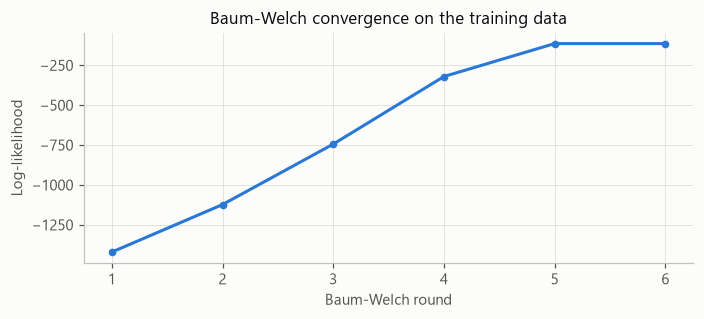

In [28]:
import copy

supervised_model = GaussianHMM(N_STATES).fit_supervised(train_sequences)
model = copy.deepcopy(supervised_model).baum_welch(train_sequences)

print(f"Converged: {model.converged} after {len(model.log_likelihoods)} rounds (limit {model.max_iter})")
print(f"Log-likelihood: {model.log_likelihoods[0]:.1f} -> {model.log_likelihoods[-1]:.1f}")
print("Rose every round:", bool((np.diff(model.log_likelihoods) > -1e-6).all()))

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(range(1, len(model.log_likelihoods) + 1), model.log_likelihoods, color=ACTIVITY_COLORS["Standing"], linewidth=2, marker="o", markersize=4)
ax.set_xlabel("Baum-Welch round")
ax.set_ylabel("Log-likelihood")
ax.set_title("Baum-Welch convergence on the training data")
fig.tight_layout()
save_figure("03_convergence")
plt.show()

### Transition matrix

The chance of staying in the same activity is 0.82-0.85, which makes sense because an activity continues for a while. The switching values are low and come from my random shuffling, so I don't read them as real habits.

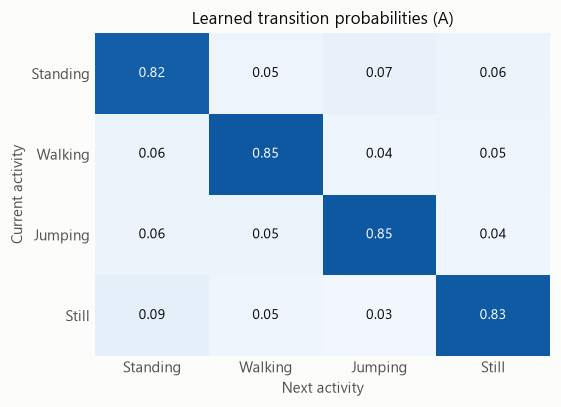

Initial probabilities (pi): {'Standing': np.float64(0.111), 'Walking': np.float64(0.444), 'Jumping': np.float64(0.222), 'Still': np.float64(0.222)}


In [29]:
def heatmap(ax, values, x_labels, y_labels, cmap="Blues", fmt="{:.2f}", vmin=None, vmax=None):
    """Draw a matrix as coloured cells, writing each value in a colour that stays readable."""
    image = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(x_labels)), x_labels)
    ax.set_yticks(range(len(y_labels)), y_labels)
    ax.grid(False)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    low, high = image.get_clim()
    middle = (low + high) / 2
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            far_from_middle = abs(values[i, j] - middle) > 0.3 * (high - low) if cmap == "RdBu_r" else values[i, j] > middle
            ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=9, color="white" if far_from_middle else INK)


fig, ax = plt.subplots(figsize=(5.2, 3.8))
heatmap(ax, model.transition, ACTIVITIES, ACTIVITIES, vmin=0, vmax=1)
ax.set_xlabel("Next activity")
ax.set_ylabel("Current activity")
ax.set_title("Learned transition probabilities (A)")
fig.tight_layout()
save_figure("04_transition_matrix")
plt.show()
print("Initial probabilities (pi):", dict(zip(ACTIVITIES, model.initial.round(3))))

### Emission probabilities

These show what each activity looks like to the model. Curves that sit apart mean that feature separates those activities well.

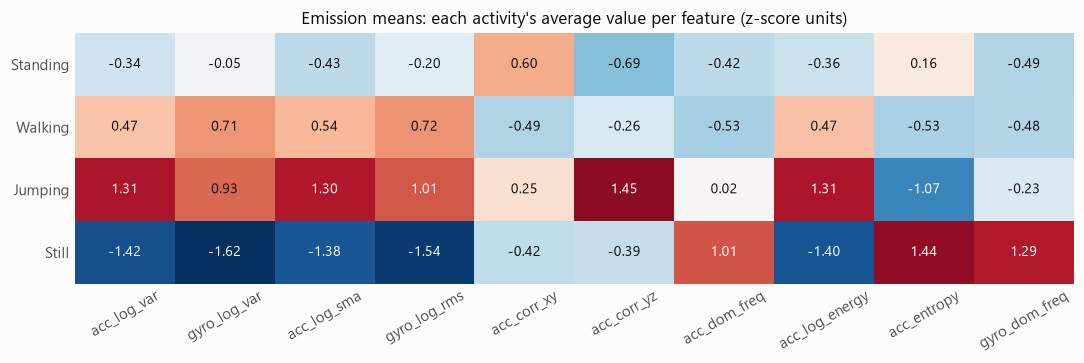

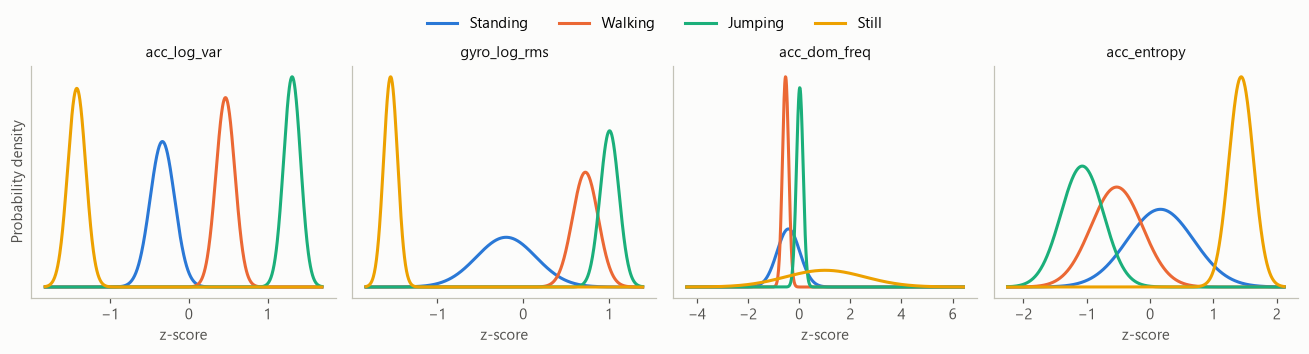

In [30]:
fig, ax = plt.subplots(figsize=(10, 3.4))
limit = np.abs(model.means).max()
heatmap(ax, model.means, FEATURE_NAMES, ACTIVITIES, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.tick_params(axis="x", labelrotation=30)
ax.set_title("Emission means: each activity's average value per feature (z-score units)")
fig.tight_layout()
save_figure("05_emission_means")
plt.show()

shown = ["acc_log_var", "gyro_log_rms", "acc_dom_freq", "acc_entropy"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for panel, name in zip(axes, shown):
    index = FEATURE_NAMES.index(name)
    centres, widths = model.means[:, index], np.sqrt(model.variances[:, index])
    grid = np.linspace((centres - 3.5 * widths).min(), (centres + 3.5 * widths).max(), 800)
    for k, activity in enumerate(ACTIVITIES):
        density = np.exp(-0.5 * ((grid - centres[k]) / widths[k]) ** 2) / (widths[k] * np.sqrt(2 * np.pi))
        panel.plot(grid, density, color=ACTIVITY_COLORS[activity], linewidth=2, label=activity)
    panel.set_title(name, fontsize=10)
    panel.set_xlabel("z-score")
    panel.set_yticks([])
    panel.grid(False)
axes[0].set_ylabel("Probability density")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
save_figure("06_emission_curves")
plt.show()

## Results on unseen data

Overall accuracy is 95.1% (78 of 82 windows). Walking and jumping are perfect. All 4 errors are Still windows from `Still_18` predicted as Standing, which is also why Standing's specificity is 0.935.

Baum-Welch lowered test accuracy from 100% to 95.1%. I still report 95.1% as the main result, because choosing a model from its test score wouldn't be a fair test.

,Number of Samples,Sensitivity,Specificity,Accuracy
State (Activity),,,,
Standing,20,1.00,0.935,0.951
Walking,21,1.00,1.000,1.000
Jumping,20,1.00,1.000,1.000
Still,21,0.81,1.000,0.951
Overall,82,NaN,NaN,0.951


,Labels only (no Baum-Welch),After Baum-Welch
Training accuracy,0.991,0.979
Test accuracy,1.000,0.951


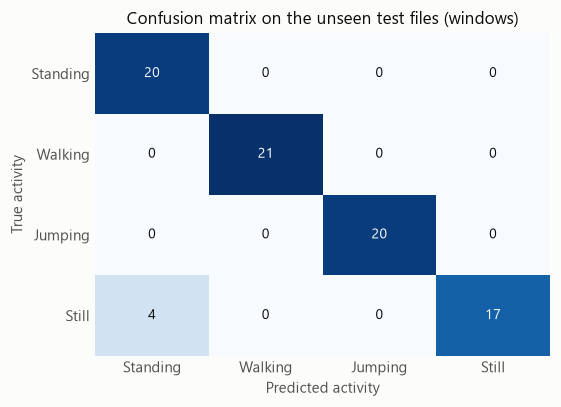

In [31]:
def confusion_matrix(true_states, predicted_states):
    """Count windows by (true state, predicted state)."""
    matrix = np.zeros((N_STATES, N_STATES), dtype=int)
    np.add.at(matrix, (true_states, predicted_states), 1)
    return matrix


def metrics_table(matrix):
    """Build the results table the assignment asks for from a confusion matrix."""
    total = matrix.sum()
    rows = []
    for k, activity in enumerate(ACTIVITIES):
        tp = matrix[k, k]
        fn = matrix[k].sum() - tp
        fp = matrix[:, k].sum() - tp
        tn = total - tp - fn - fp
        rows.append({"State (Activity)": activity, "Number of Samples": tp + fn,
                     "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                     "Accuracy": (tp + tn) / total})
    rows.append({"State (Activity)": "Overall", "Number of Samples": total,
                 "Sensitivity": np.nan, "Specificity": np.nan, "Accuracy": np.trace(matrix) / total})
    return pd.DataFrame(rows).set_index("State (Activity)").round(3)


def decode_all(hmm, sequences):
    """Run Viterbi on each sequence and join the true and predicted states."""
    true_states = np.concatenate([y for _, y in sequences])
    predictions = np.concatenate([hmm.viterbi(X) for X, _ in sequences])
    return true_states, predictions


test_true, test_pred = decode_all(model, test_sequences.values())
test_confusion = confusion_matrix(test_true, test_pred)
results = metrics_table(test_confusion)
results.to_csv("results_table.csv")

comparison = pd.DataFrame({
    "Labels only (no Baum-Welch)": {
        "Training accuracy": np.mean(np.equal(*decode_all(supervised_model, train_sequences))),
        "Test accuracy": np.mean(np.equal(*decode_all(supervised_model, test_sequences.values()))),
    },
    "After Baum-Welch": {
        "Training accuracy": np.mean(np.equal(*decode_all(model, train_sequences))),
        "Test accuracy": np.mean(test_true == test_pred),
    },
}).round(3)
display(results)
display(comparison)

fig, ax = plt.subplots(figsize=(5.2, 3.8))
heatmap(ax, test_confusion, ACTIVITIES, ACTIVITIES, fmt="{:d}")
ax.set_xlabel("Predicted activity")
ax.set_ylabel("True activity")
ax.set_title("Confusion matrix on the unseen test files (windows)")
fig.tight_layout()
save_figure("07_confusion_matrix")
plt.show()

### Decoded sequences

True activity against the Viterbi prediction. The confidence stays close to 1 even during the errors, so the model is overconfident.

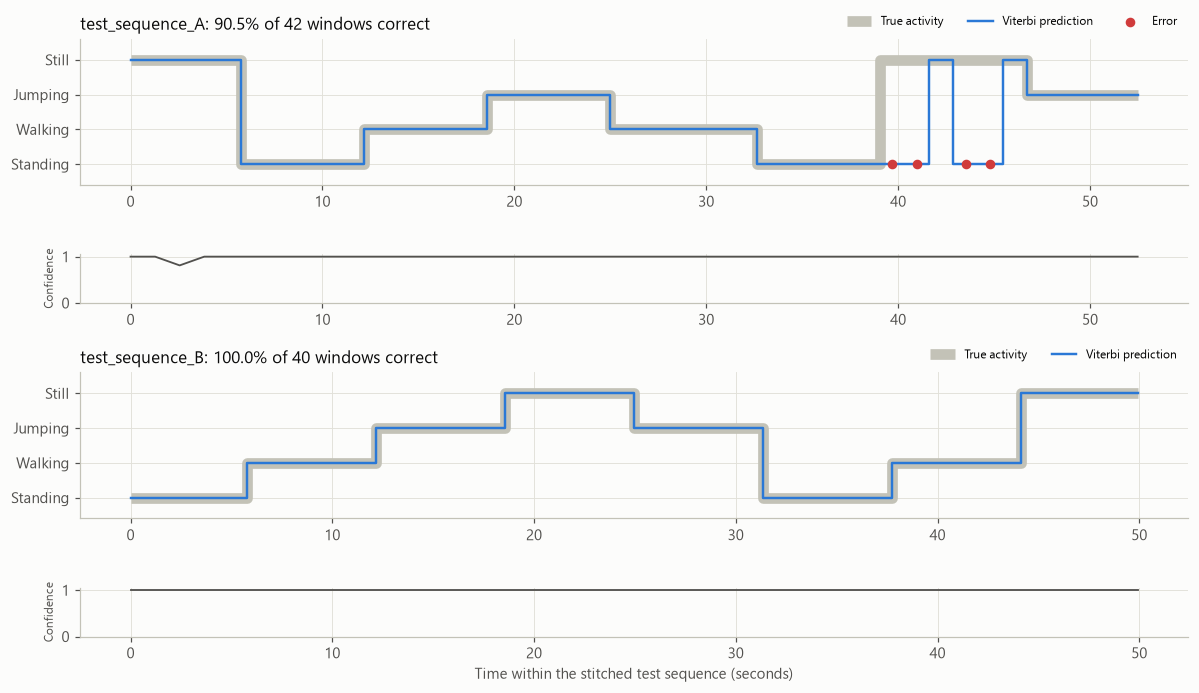

In [32]:
fig, axes = plt.subplots(4, 1, figsize=(11, 6.4), gridspec_kw={"height_ratios": [3, 1, 3, 1]})
for i, (name, (X, y)) in enumerate(test_sequences.items()):
    path = model.viterbi(X)
    confidence = model.posteriors(X)[np.arange(len(X)), path]
    time = np.arange(len(X)) * WINDOW_STEP / TARGET_HZ
    top, bottom = axes[2 * i], axes[2 * i + 1]

    top.step(time, y, where="mid", color="#c3c2b7", linewidth=7, solid_capstyle="butt", label="True activity")
    top.step(time, path, where="mid", color=ACTIVITY_COLORS["Standing"], linewidth=1.6, label="Viterbi prediction")
    wrong = path != y
    if wrong.any():
        top.scatter(time[wrong], path[wrong], color="#d03b3b", s=28, zorder=3, label="Error")
    top.set_yticks(range(N_STATES), ACTIVITIES)
    top.set_ylim(-0.6, N_STATES - 0.4)
    top.set_title(f"{name}: {np.mean(path == y):.1%} of {len(y)} windows correct", loc="left")
    top.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=3, fontsize=8)

    bottom.plot(time, confidence, color=MUTED, linewidth=1.2)
    bottom.set_ylim(0, 1.05)
    bottom.set_ylabel("Confidence", fontsize=8)
axes[-1].set_xlabel("Time within the stitched test sequence (seconds)")
fig.tight_layout()
save_figure("08_decoded_sequences")
plt.show()

## Cross-validation

With only 16 test recordings, I also checked all 80 using 5 folds. Accuracy is 97.5%, close to the test result. Still is again the weakest activity, with sensitivity of 0.914.

The test data comes from the same phone, the same person and the same sessions as training, so this result may not hold for other people or phones. A continuous recording on a new day would be a better test.

In [33]:
def train_and_decode(train_list, test_list):
    """Run the whole pipeline on a split. Test recordings are decoded one at a time."""
    fold_scaler = make_scaler(train_list)
    hmm = GaussianHMM(N_STATES).fit_supervised(make_sequences(train_list, fold_scaler)).baum_welch(make_sequences(train_list, fold_scaler))
    outcomes = {}
    for name in test_list:
        X, y = to_arrays([features_by_recording[name]], fold_scaler)
        outcomes[name] = (y, hmm.viterbi(X))
    return outcomes


cv_outcomes = {}
for fold in range(5):
    fold_test = [name for name in recordings if (recording_number(name) - 1) % 5 == fold]
    fold_train = [name for name in recordings if name not in fold_test]
    cv_outcomes.update(train_and_decode(fold_train, fold_test))

cv_true = np.concatenate([y for y, _ in cv_outcomes.values()])
cv_pred = np.concatenate([p for _, p in cv_outcomes.values()])
display(metrics_table(confusion_matrix(cv_true, cv_pred)))

mistakes = {name: f"{(p != y).sum()} of {len(y)} windows wrong, predicted {sorted({ACTIVITIES[s] for s in p[p != y]})}"
            for name, (y, p) in cv_outcomes.items() if (p != y).any()}
print("Recordings with mistakes:", mistakes if mistakes else "none")

,Number of Samples,Sensitivity,Specificity,Accuracy
State (Activity),,,,
Standing,103,0.990,0.970,0.975
Walking,102,1.000,0.997,0.998
Jumping,98,1.000,1.000,1.000
Still,105,0.914,1.000,0.978
Overall,408,NaN,NaN,0.975


Recordings with mistakes: {'Standing_07': "1 of 5 windows wrong, predicted ['Walking']", 'Still_02': "1 of 6 windows wrong, predicted ['Standing']", 'Still_07': "1 of 5 windows wrong, predicted ['Standing']", 'Still_17': "1 of 5 windows wrong, predicted ['Standing']", 'Still_08': "2 of 5 windows wrong, predicted ['Standing']", 'Still_18': "4 of 6 windows wrong, predicted ['Standing']"}
